# 06 · Segurança: como BH se posiciona, e renda mais alta significa mais segurança?

> Parte 6 de 6 do projeto *BH e Região sob a perspectiva dos dados*. Veja o [README](../README.md) para a visão geral.

In [1]:
# Configuração: funciona no computador (a partir da pasta notebooks/) e no Google Colab
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/ips-bh-rmbh')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/millebns/ips-bh-rmbh.git', str(repo)], check=True)
    os.chdir(repo / 'notebooks')

sys.path.insert(0, str(Path.cwd().parent / 'src'))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from functools import partial

from ips_rmbh import analise
from ips_rmbh.config import BH, COR_BH, COR_OUTROS, COR_DESTAQUE, PASTA_FIGURAS
from ips_rmbh.dados import carregar_rmbh

df_rmbh = carregar_rmbh()

# Atalhos que comparam BH com os demais municípios da RMBH
posicao_bh = partial(analise.posicao, df_rmbh)
valor_bh = partial(analise.valor, df_rmbh)
print(df_rmbh.shape)

(34, 78)


In [3]:
print(f"Segurança Pessoal: BH {posicao_bh('Segurança Pessoal')}º de 34 | "
      f"nota {valor_bh('Segurança Pessoal'):.2f} | mediana {df_rmbh['Segurança Pessoal'].median():.2f}")

Segurança Pessoal: BH 15º de 34 | nota 67.41 | mediana 67.00


Os indicadores do componente Segurança Pessoal são taxas, então menor é melhor. As violências contra mulheres, negros e indígenas pertencem ao componente Inclusão Social (analisado na pergunta 2), e não a Segurança Pessoal.

In [4]:
seguranca = ['Homicídios', 'Assassinatos de Jovens', 'Assassinatos de Mulheres',
             'Mortes por Acidentes de Transporte']

pd.DataFrame([{
    'indicador': c,
    'BH': round(valor_bh(c), 2),
    'mediana_RMBH': round(df_rmbh[c].median(), 2),
    'posicao_BH': posicao_bh(c, maior_melhor=False),
} for c in seguranca])

,indicador,BH,mediana_RMBH,posicao_BH
0,Homicídios,13.91,14.00,16
1,Assassinatos de Jovens,30.31,28.95,19
2,Assassinatos de Mulheres,2.35,2.41,17
3,Mortes por Acidentes de Transporte,10.91,5.68,26


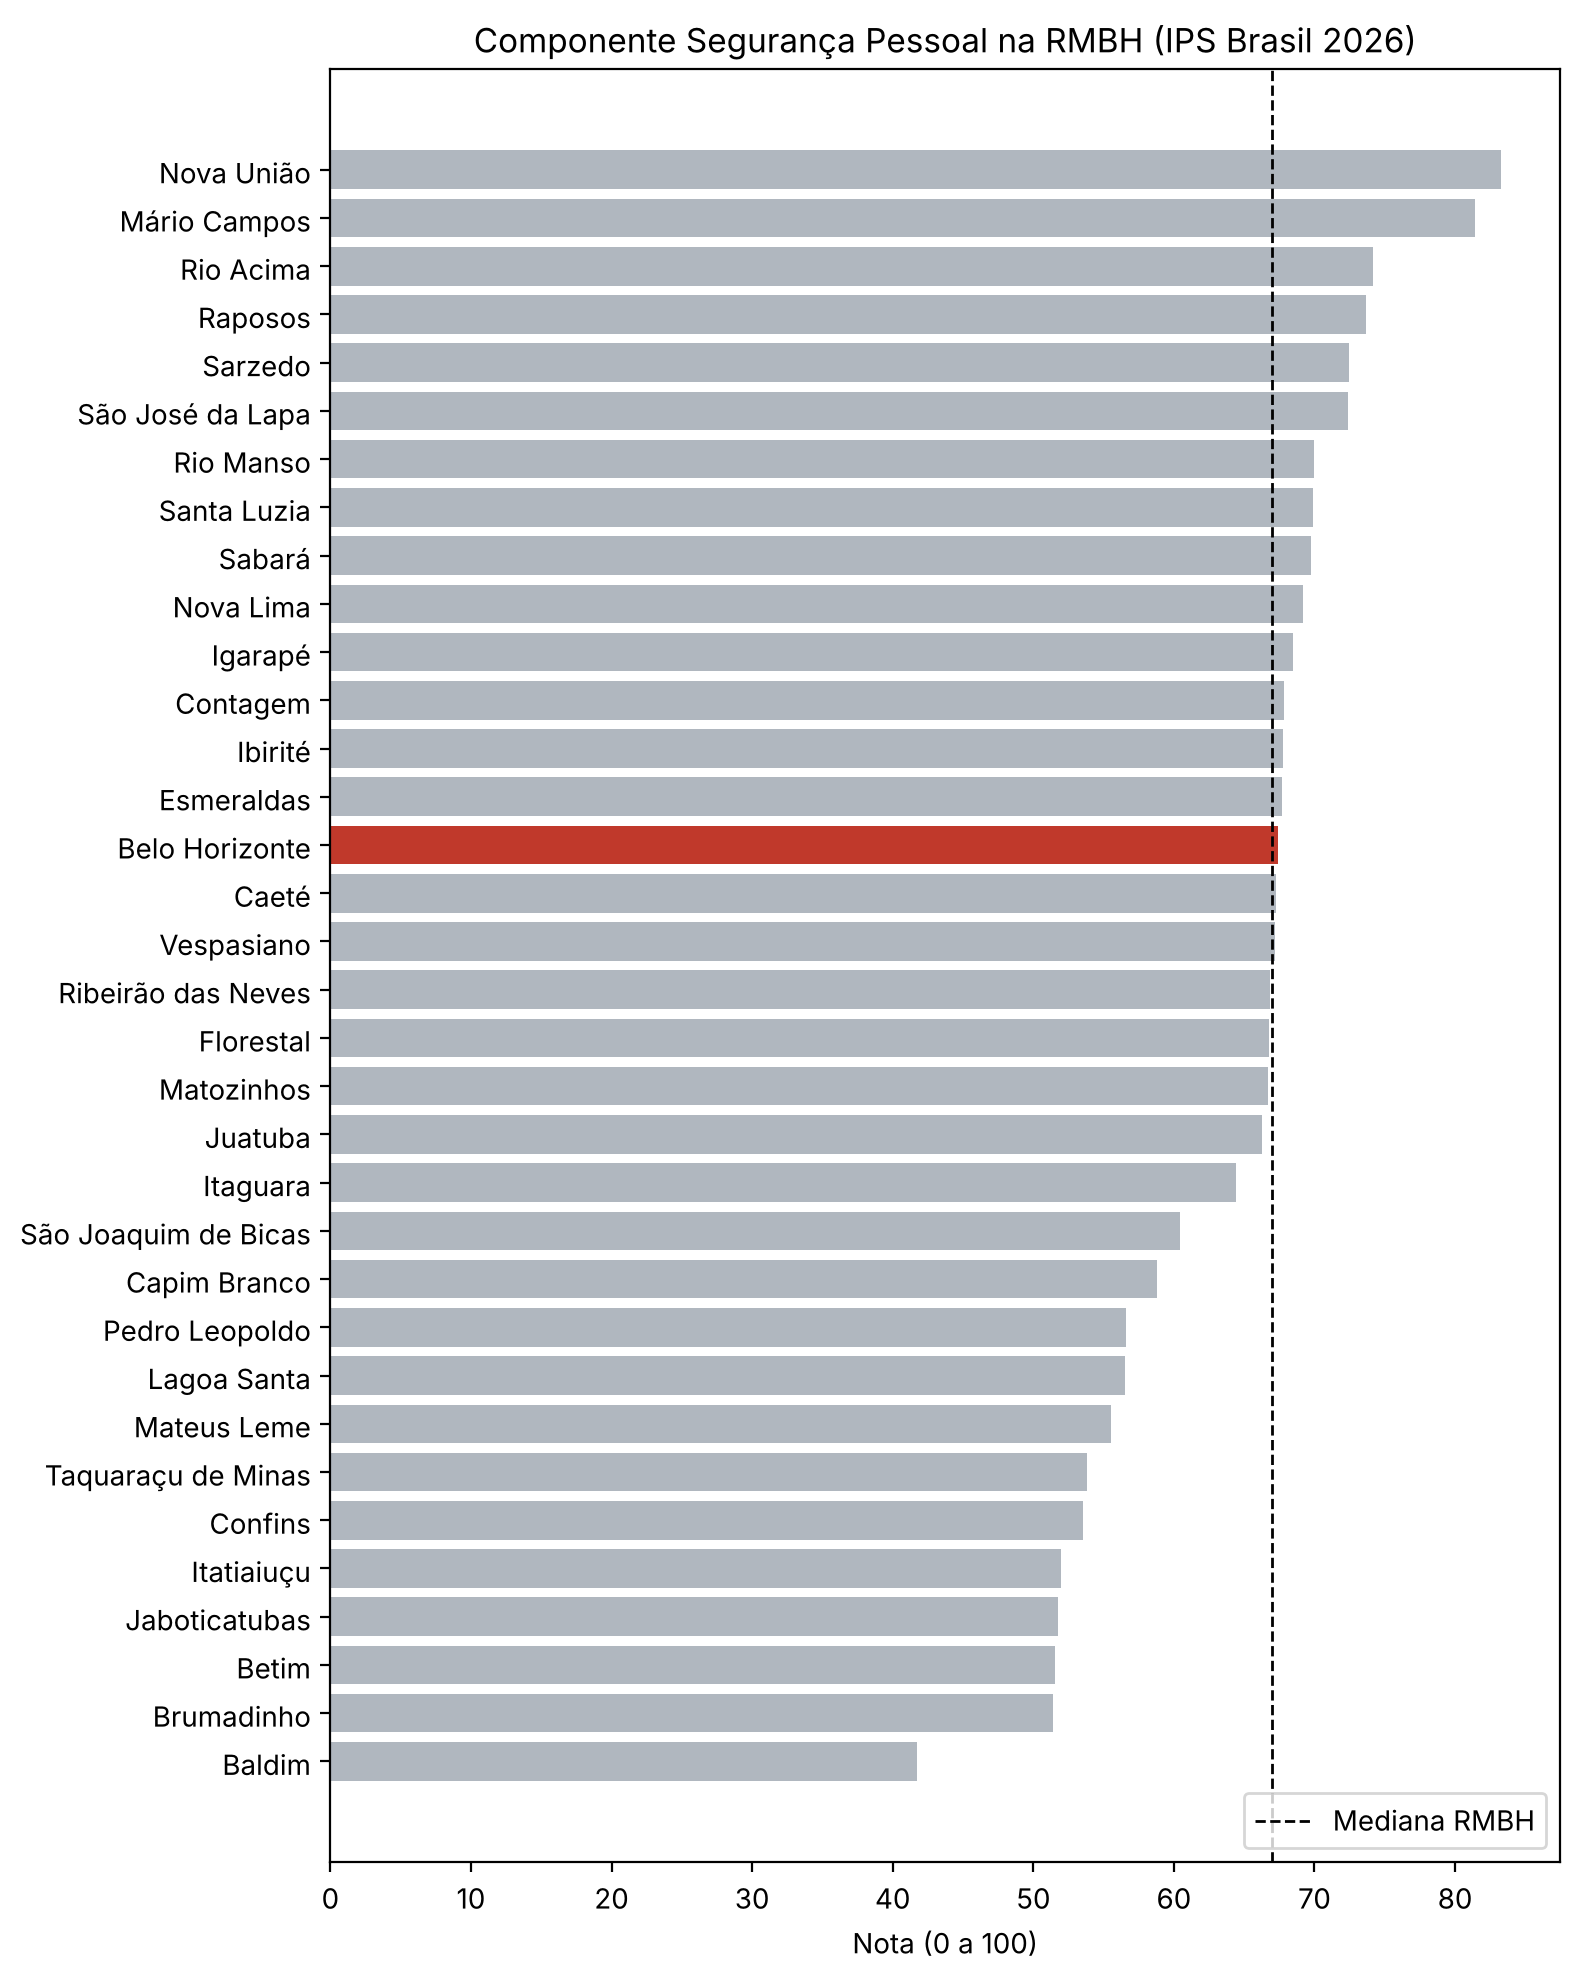

In [5]:
seg = df_rmbh[['Município', 'Segurança Pessoal']].sort_values('Segurança Pessoal')

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(seg['Município'], seg['Segurança Pessoal'],
        color=[COR_BH if m == BH else COR_OUTROS for m in seg['Município']])
ax.axvline(seg['Segurança Pessoal'].median(), ls='--', c='black', lw=1, label='Mediana RMBH')
ax.set_title('Componente Segurança Pessoal na RMBH (IPS Brasil 2026)')
ax.set_xlabel('Nota (0 a 100)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '04_seguranca_rmbh.png', dpi=150, bbox_inches='tight')
plt.show()

Resposta: BH fica no meio da tabela em segurança (15ª de 34), com nota praticamente igual à mediana. A taxa de homicídios de BH (13,9) é quase idêntica à mediana regional (14,0). O indicador em que BH vai pior são as mortes por acidentes de transporte (10,9 contra 5,7; 26ª posição). As menores notas de segurança da região estão em Baldim, Brumadinho e Betim.

# Renda mais alta significa mais segurança?

Para testar a relação entre riqueza e segurança, comparamos o PIB per capita com a nota do componente Segurança Pessoal e com cada um dos seus indicadores, nos 34 municípios da RMBH.

Usamos duas medidas de correlação:
- **Pearson com o log do PIB**, a mesma usada na comparação IPS x PIB (notebook 05);
- **Spearman**, que compara só as posições no ranking e é menos sensível a valores extremos, como o PIB de Confins e Itatiaiuçu.

**Leitura dos sinais:** na nota de Segurança Pessoal, maior é melhor. Então uma correlação **negativa** significa que municípios mais ricos têm segurança **pior**. Nos indicadores (taxas), menor é melhor, e uma correlação **positiva** significa taxas mais altas nos municípios mais ricos.

In [6]:
import numpy as np

log_pib = np.log10(df_rmbh['PIB PER CAPITA'])
colunas = ['Segurança Pessoal'] + seguranca

correlacoes = pd.DataFrame([{
    'item': c,
    'pearson_log_pib': round(np.corrcoef(log_pib, df_rmbh[c])[0, 1], 2),
    'spearman_pib': round(df_rmbh['PIB PER CAPITA'].corr(df_rmbh[c], method='spearman'), 2),
} for c in colunas])
correlacoes

,item,pearson_log_pib,spearman_pib
0,Segurança Pessoal,-0.30,-0.25
1,Homicídios,0.20,0.16
2,Assassinatos de Jovens,0.25,0.21
3,Assassinatos de Mulheres,0.20,0.27
4,Mortes por Acidentes de Transporte,0.36,0.32


In [7]:
# Onde ficam em segurança os 5 municípios com maior PIB per capita?
ricos = df_rmbh[['Município', 'PIB PER CAPITA', 'Segurança Pessoal']].copy()
ricos['posicao_PIB'] = ricos['PIB PER CAPITA'].rank(ascending=False, method='min').astype(int)
ricos['posicao_seguranca'] = ricos['Segurança Pessoal'].rank(ascending=False, method='min').astype(int)
ricos.sort_values('posicao_PIB').head(5).round(2).reset_index(drop=True)

,Município,PIB PER CAPITA,Segurança Pessoal,posicao_PIB,posicao_seguranca
0,Confins,208432.20,53.53,1,29
1,Itatiaiuçu,176687.35,52.00,2,30
2,Betim,121952.48,51.52,3,32
3,Nova Lima,102907.19,69.16,4,10
4,Brumadinho,69246.29,51.39,5,33


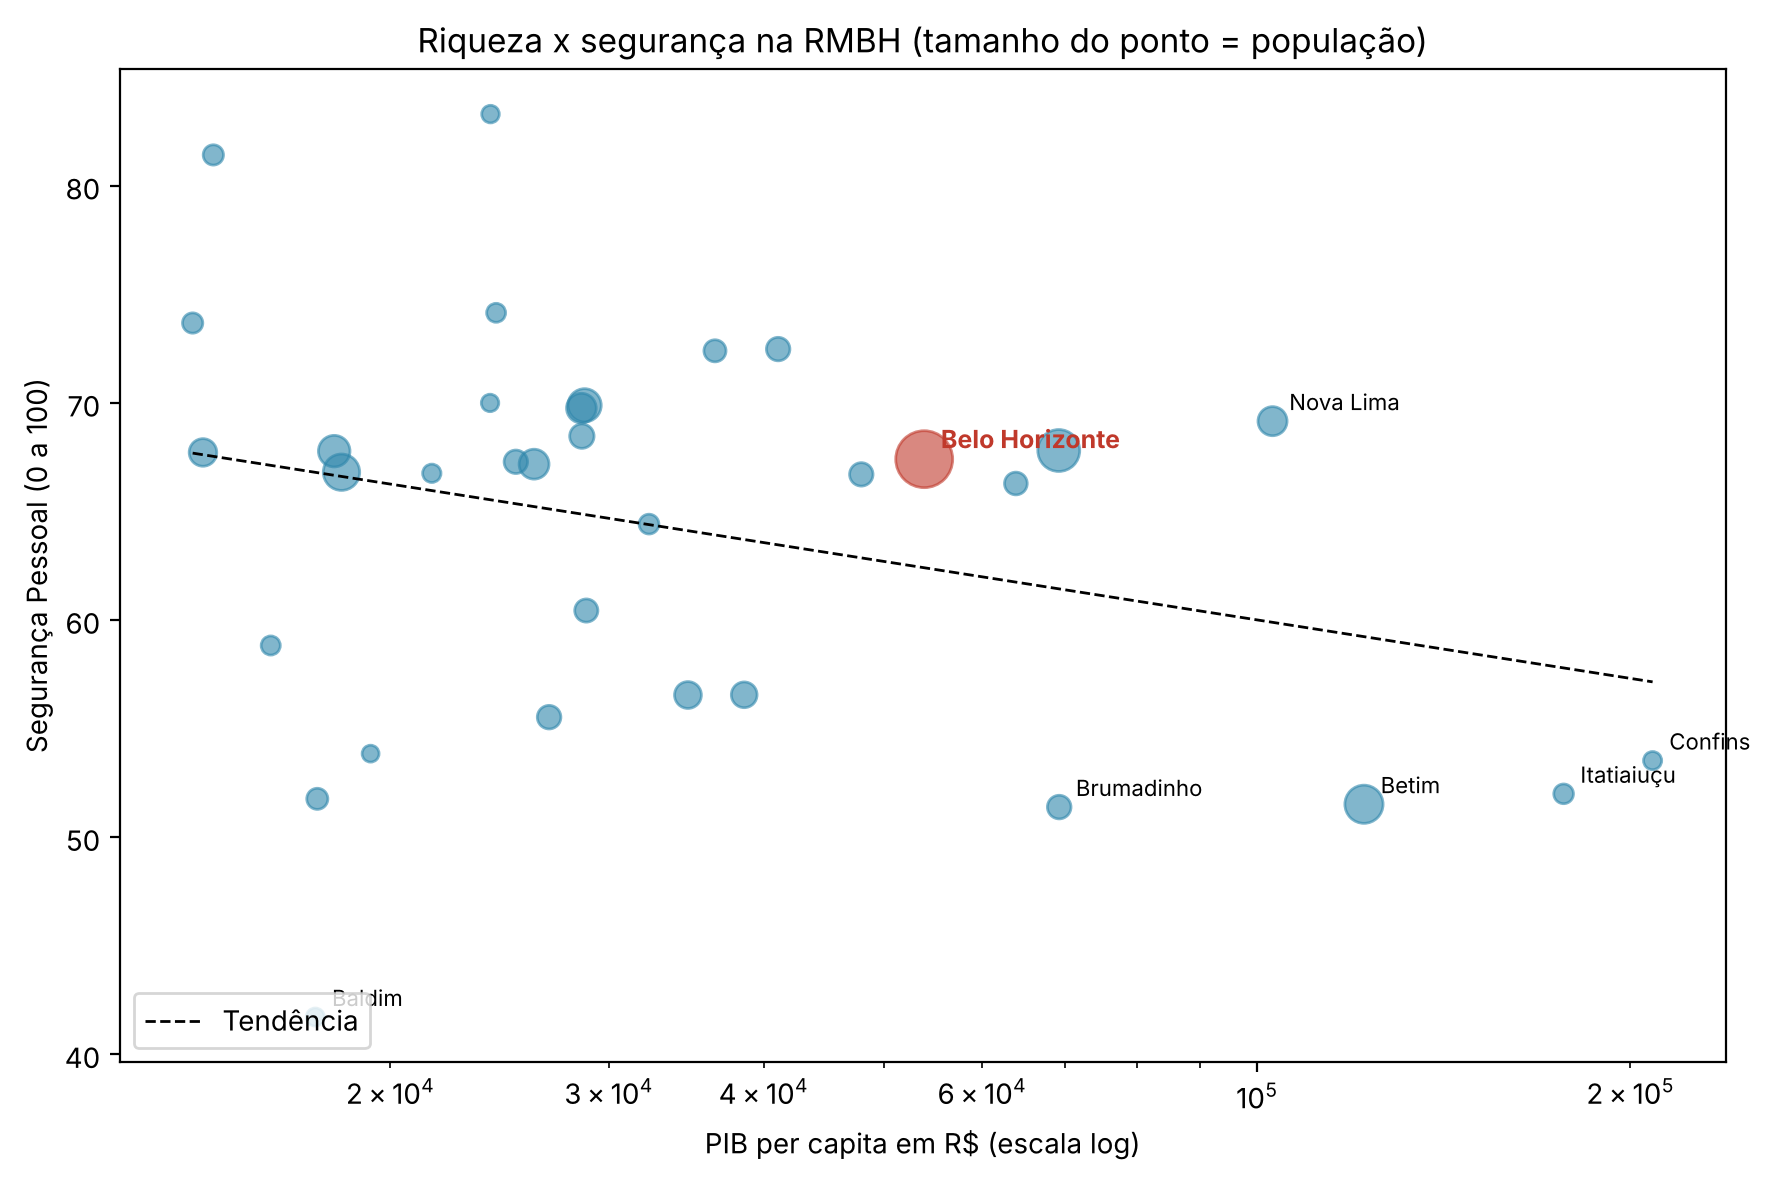

In [8]:
destaques = ['Belo Horizonte', 'Nova Lima', 'Confins', 'Itatiaiuçu', 'Betim', 'Brumadinho', 'Baldim']
tamanho = 20 + 400 * (df_rmbh['POPULAÇÃO 2025'] / df_rmbh['POPULAÇÃO 2025'].max()) ** 0.5
coef = np.polyfit(log_pib, df_rmbh['Segurança Pessoal'], 1)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_rmbh['PIB PER CAPITA'], df_rmbh['Segurança Pessoal'], s=tamanho, alpha=0.6,
           c=[COR_BH if m == BH else COR_DESTAQUE for m in df_rmbh['Município']])
xs = np.linspace(log_pib.min(), log_pib.max(), 50)
ax.plot(10 ** xs, np.polyval(coef, xs), c='black', lw=1, ls='--', label='Tendência')
for _, r in df_rmbh[df_rmbh['Município'].isin(destaques)].iterrows():
    eh_bh = r['Município'] == BH
    ax.annotate(r['Município'], (r['PIB PER CAPITA'], r['Segurança Pessoal']),
                xytext=(6, 4), textcoords='offset points', fontsize=9 if eh_bh else 8,
                fontweight='bold' if eh_bh else 'normal', color=COR_BH if eh_bh else 'black')
ax.set_xscale('log')
ax.set_xlabel('PIB per capita em R$ (escala log)')
ax.set_ylabel('Segurança Pessoal (0 a 100)')
ax.set_title('Riqueza x segurança na RMBH (tamanho do ponto = população)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '05_seguranca_x_pib.png', dpi=150, bbox_inches='tight')
plt.show()

**Resposta:** não. Na RMBH, renda mais alta **não** vem acompanhada de mais segurança. A relação é fraca e vai no sentido contrário ao esperado: a correlação entre o PIB per capita e a nota de Segurança Pessoal é negativa (−0,30 com o log do PIB; −0,25 por Spearman). Todos os indicadores de violência e de mortes no trânsito têm correlação positiva com o PIB, ou seja, taxas um pouco mais altas nos municípios mais ricos. A mais forte é a de mortes por acidentes de transporte (0,36).

O exemplo mais claro: dos 5 municípios com maior PIB per capita, 4 estão entre os 6 piores em segurança (Confins, Itatiaiuçu, Betim e Brumadinho). A exceção é Nova Lima, 10ª em segurança.

**Cuidados na leitura:** são só 34 municípios, as correlações são fracas e associação não é causa. Em municípios pequenos, como Confins e Itatiaiuçu, poucos casos já mudam bastante as taxas.

# Conclusões do projeto

1. **BH está entre os maiores IPS da RMBH:** 3ª de 34, praticamente empatada com Confins e atrás de Nova Lima.
2. **O índice alto esconde um perfil desigual:** BH lidera em educação superior, direitos individuais e saneamento, mas é a última em inclusão social, puxada pela população em situação de rua. Em relação à riqueza, BH tem progresso social acima do esperado para o seu PIB per capita.
3. **Em segurança, BH é mediana:** homicídios no nível da região, com pior desempenho nas mortes no trânsito.
4. **Renda mais alta não significa mais segurança:** na RMBH, municípios com maior PIB per capita tendem a ter notas de segurança um pouco piores, e não melhores.

## Limitações

- A análise usa apenas a edição 2026. As edições anteriores não são comparáveis por nota, como mostrado na exploração inicial.
- Municípios pequenos têm taxas mais instáveis, o que afeta a leitura de posições próximas no ranking.
- As relações do IPS e da segurança com o PIB são associações entre 34 municípios, não relações de causa.